In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("loan.csv")

In [5]:
df.head(3)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [8]:
df.shape

(614, 13)

# **DETECTING OUTLIERS**

In [7]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


<Axes: xlabel='CoapplicantIncome'>

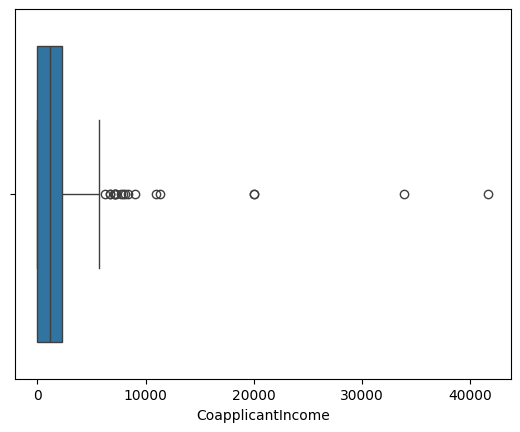

In [12]:
# using boxplot for the detection of outliers in COAPPLICANT INCOME
sns.boxplot(x = 'CoapplicantIncome' , data = df)

<Axes: xlabel='ApplicantIncome'>

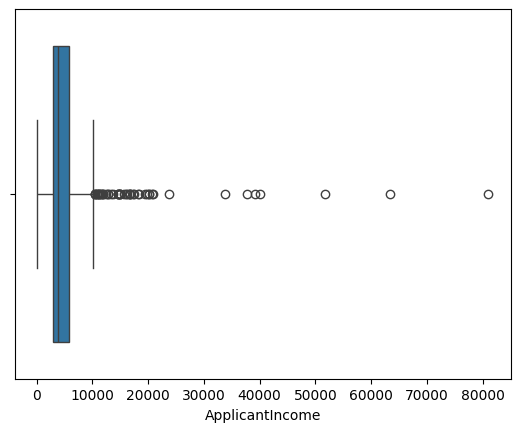

In [14]:
# using boxplot for the detection of outliers in APPLICANT INCOME
sns.boxplot(x = 'ApplicantIncome' , data = df)

/tmp/ipykernel_2527/3783519777.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['ApplicantIncome'])


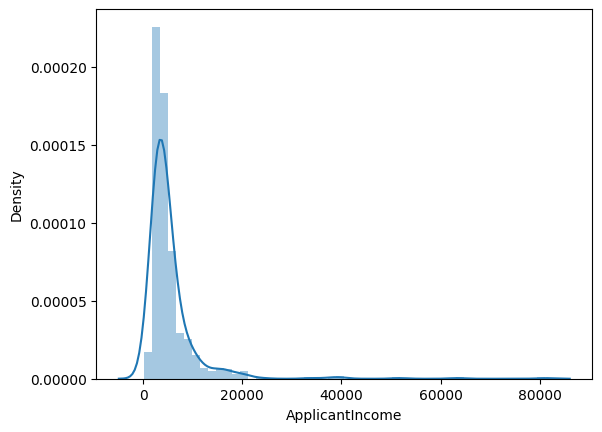

In [15]:
# outlier detection using distplot
sns.distplot(df['ApplicantIncome'])
plt.show()

/tmp/ipykernel_2527/1895390374.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['CoapplicantIncome'])


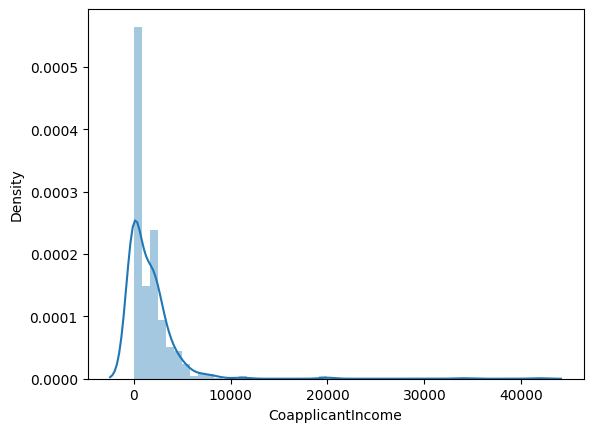

In [16]:
# outlier detection using distplot
sns.distplot(df['CoapplicantIncome'])
plt.show()

# **REMOVING OUTLIERS**

USING IQR -> inter-quantile-range  -> Q3 - Q1

min : Q1 - (1.5 * IQR)   --> 25 % of data

max : Q3 + (1.5 * IQR)   --> 75 % of data



In [18]:
# for coapplicant income
q1 = df['CoapplicantIncome'].quantile(0.25)
q3 = df['CoapplicantIncome'].quantile(0.75)
print(q1)
print(q3)

0.0
2297.25


In [19]:
IQR = q3 - q1
print(IQR)

2297.25


In [22]:
min_range = q1 - (1.5 * IQR)
max_range = q3 + (1.5 * IQR)
min_range , max_range

(np.float64(-3445.875), np.float64(5743.125))

In [24]:
new_dataset = df[df['CoapplicantIncome'] <= max_range]

In [25]:
new_dataset.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [26]:
new_dataset.shape

(596, 13)

In [28]:
new_dataset.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,596.000000,596.00000,574.000000,582.00000,549.000000
mean,5403.332215,1289.12906,142.871080,342.57732,0.843352
std,6142.754002,1461.72508,81.169683,64.98370,0.363800
min,150.000000,0.00000,9.000000,12.00000,0.000000
25%,2894.750000,0.00000,100.000000,360.00000,1.000000
50%,3812.500000,1031.00000,126.000000,360.00000,1.000000
75%,5754.500000,2173.00000,161.750000,360.00000,1.000000
max,81000.000000,5701.00000,700.000000,480.00000,1.000000


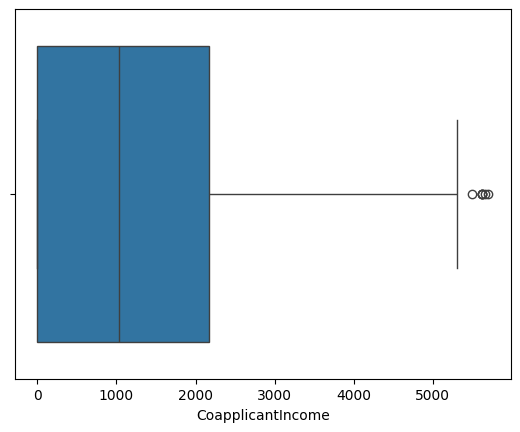

In [33]:
sns.boxplot(x = 'CoapplicantIncome' , data = new_dataset)
plt.show()

USING Z-SCORE

In [34]:
dataset = pd.read_csv("loan.csv")

In [35]:
dataset.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [36]:
dataset.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


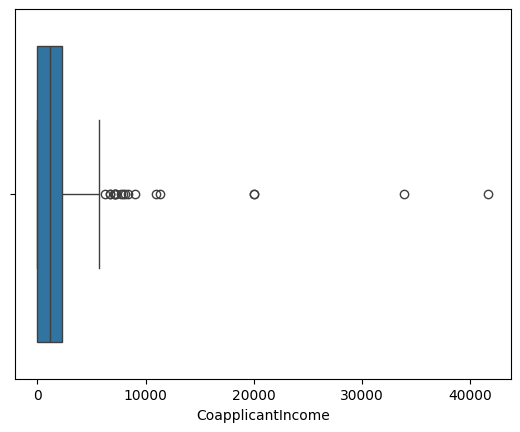

In [37]:
sns.boxplot(x = 'CoapplicantIncome' , data = dataset)
plt.show()

/tmp/ipykernel_2527/3783729653.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dataset['CoapplicantIncome'])


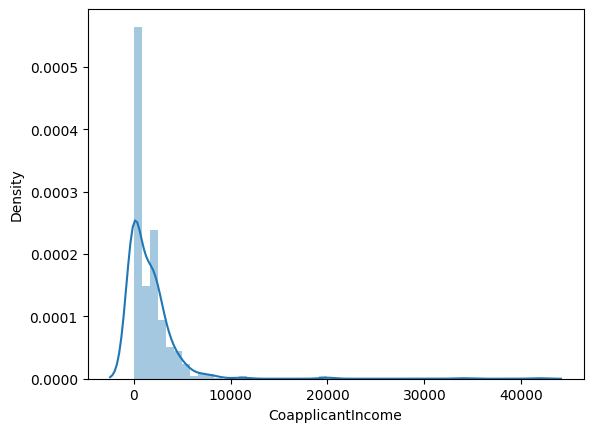

In [38]:
sns.distplot(dataset['CoapplicantIncome'])
plt.show()

In [40]:
# 3rd standard deviation
min_range = dataset['CoapplicantIncome'].mean() - ( 3 * dataset['CoapplicantIncome'].std() )
max_range = dataset['CoapplicantIncome'].mean() + ( 3 * dataset['CoapplicantIncome'].std() )
min_range , max_range

(np.float64(-7157.499309645475), np.float64(10399.990905699677))

In [41]:
new_dataset = dataset[ dataset['CoapplicantIncome'] <= max_range]

In [42]:
new_dataset.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,608.000000,608.000000,586.000000,594.000000,559.000000
mean,5416.143092,1410.646250,145.136519,342.121212,0.842576
std,6123.586316,1685.286222,83.825124,65.088956,0.364526
min,150.000000,0.000000,9.000000,12.000000,0.000000
25%,2892.750000,0.000000,100.000000,360.000000,1.000000
50%,3813.500000,1125.500000,127.500000,360.000000,1.000000
75%,5803.750000,2250.750000,165.750000,360.000000,1.000000
max,81000.000000,8980.000000,700.000000,480.000000,1.000000


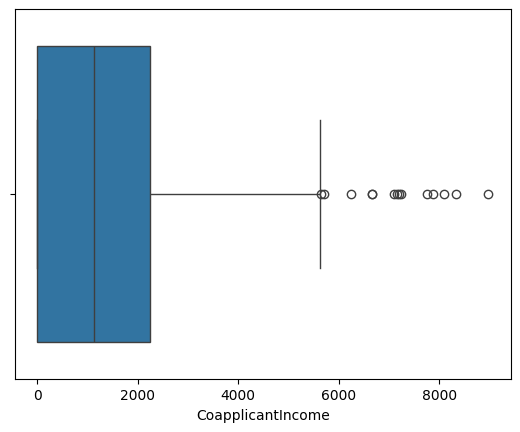

In [43]:
sns.boxplot(x = 'CoapplicantIncome' , data = new_dataset)
plt.show()

In [44]:
z_score = ( dataset['CoapplicantIncome'] - dataset['CoapplicantIncome'].mean() ) / dataset['CoapplicantIncome'].std()

In [45]:
z_score

,CoapplicantIncome
0,-0.554036
1,-0.038700
2,-0.554036
3,0.251774
4,-0.554036
...,...
609,-0.554036
610,-0.554036
611,-0.472019
612,-0.554036


In [46]:
z_score < 3

,CoapplicantIncome
0,True
1,True
2,True
3,True
4,True
...,...
609,True
610,True
611,True
612,True


In [47]:
# inserting this z_score column in the original dataset
dataset["z_score"] = z_score

In [48]:
dataset

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,z_score
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,-0.554036
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,-0.038700
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,-0.554036
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,0.251774
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,-0.554036
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y,-0.554036
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y,-0.554036
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y,-0.472019
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y,-0.554036


In [49]:
# removing outliers  : value of z lies between -3 to +3
dataset[dataset["z_score"] < 3]

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,z_score
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,-0.554036
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,-0.038700
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,-0.554036
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,0.251774
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,-0.554036
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y,-0.554036
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y,-0.554036
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y,-0.472019
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y,-0.554036
